# Day 4 lecture: Data mining with text features

<p class="lead">
Much of what a business knows is written down: product listings, reviews, agent notes, support tickets. This lecture shows how data mining turns that text into numbers a model can use (keyword flags, word counts and sentiment scores), how to test whether those numbers really improve a prediction, and what can go wrong. It ends with the briefing for Assignment 2.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**.

---

## What you will be able to do

1. Describe **data mining** as a process, and tell **supervised** from **unsupervised** methods.
2. Explain the difference between **structured** and **unstructured** data.
3. Turn text into **features**: keyword flags, a bag of words, and a **sentiment score**.
4. Test whether text features improve a regression by comparing **test** errors with and without them.
5. Explain why a general-purpose sentiment score can misread a specialised text, and spot **data leakage**.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. **Check your understanding** boxes are short questions to answer in your own words.

| Part | Topic |
|---|---|
| 1 | What data mining is |
| 2 | Structured and unstructured data |
| 3 | The case: second-hand bicycle listings |
| 4 | Text into numbers: sentiment, keywords, bag of words |
| 5 | Do the text features help? |
| 6 | Pitfalls: misreadings, leakage and fairness |
| 7 | Assignment 2 briefing |

---

## Part 1: What data mining is

**Data mining** is the search for useful, reliable patterns in large amounts of data. It uses the methods you already know (summaries, charts, correlation, regression) and some new ones, inside a repeatable process:

| Step | Question | Example |
|---|---|---|
| 1. Business understanding | What decision will the result support? | Price a second-hand bicycle fairly |
| 2. Data understanding | What data exist, and how good are they? | Listings with age, original price and a written description |
| 3. Data preparation | How do we turn raw data into features? | **Turn the description into numbers** |
| 4. Modelling | Which method finds the pattern? | Multiple linear regression |
| 5. Evaluation | Does it work on new cases? | Test-set error compared with a simpler model |
| 6. Deployment | How is it used, and monitored? | Suggested price shown to sellers |

This is the CRISP-DM process, widely used in industry. Most of the effort usually goes into steps 2 and 3.

| Family | Has a known target? | Examples |
|---|---|---|
| **Supervised** | Yes: learn to predict it | Regression (price, MPG), classification (will the customer leave?) |
| **Unsupervised** | No: find structure | Clustering customers into segments, finding words that appear together |

Today's case is supervised: we predict a price.

---

## Part 2: Structured and unstructured data

| | Structured | Unstructured |
|---|---|---|
| Shape | Rows and columns with fixed meaning | Free text, images, audio |
| Example | Age of a bicycle: 3.5 years | "Recently serviced, a few small scratches, rides well." |
| Ready for a model? | Yes | No: it must first be turned into numbers (**feature engineering**) |

The description often contains information that no column holds: the **condition** of the item. A seller who writes "needs repair: rear wheel is bent" is telling buyers something that age and original price cannot.

On Day 3 you cleaned text, counted words and scored sentiment with VADER. Today we use those same tools to create **features** for a predictive model.

The setup cell loads the libraries and points NLTK at the bundled VADER lexicon, so no internet is needed.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"
INK = "#55534e"
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 120)

---

## Part 3: The case: second-hand bicycle listings

> **About the data**
>
> The listings are **synthetic**: generated in the next cell for this course, describing no real marketplace or seller. Prices are in neutral **currency units**.

**RideAgain** runs a website where people sell used bicycles. It wants to suggest a fair asking price to each seller. For every past sale it has:

| Column | Type | Meaning |
|---|---|---|
| `age_years` | Structured | Age of the bicycle in years |
| `new_price` | Structured | The price of the same model when new |
| `description` | **Unstructured** | What the seller wrote |
| `price` | Target | The price it actually sold for |

The data are generated so that the **true** condition of each bicycle (which RideAgain does not record) affects both the price and what the seller writes. Some sellers also add friendly sentences that say nothing about condition. The question is whether text mining can recover the condition from the words.

In [3]:
rng = np.random.default_rng(seed=2026)
n = 600

# Sentences sellers use, by the bicycle's true condition (not recorded by the website)
PHRASES = {
    "excellent": ["Like new, barely ridden.", "Recently serviced and runs perfectly.",
                  "New tyres and new chain, always stored indoors.", "Hardly used, no scratches at all."],
    "good": ["Good condition with normal signs of use.", "A few small scratches but rides well.",
             "Reliable commuter bike, serviced last year.", "Some wear on the saddle, otherwise fine."],
    "worn": ["Well used, some rust on the chain.", "Brakes are worn and need adjusting.",
             "Paint is scratched and faded.", "Rust on the frame, gears slip sometimes."],
    "needs repair": ["Needs repair: the rear wheel is bent.", "Gears do not shift. Sold as is.",
                     "Flat tyres, broken light and a cracked saddle.", "Spares or repair only, frame is dented."],
}
FILLER = ["Great bike for the city!", "Collection only.", "Comes with a lock.",
          "Love this bike, sad to sell it!", "Medium frame.", "Price is firm.", "", ""]
VALUE_KEPT = {"excellent": 1.0, "good": 0.85, "worn": 0.65, "needs repair": 0.4}

condition = rng.choice(list(PHRASES), size=n, p=[0.25, 0.35, 0.25, 0.15])
age = rng.uniform(0.5, 10, n).round(1)
new_price = rng.choice([400, 700, 1000, 1500, 2500], size=n)

descriptions = []
for c in condition:
    k = rng.integers(1, 3)   # one or two sentences about condition
    sentences = list(rng.choice(PHRASES[c], size=k, replace=False)) + [rng.choice(FILLER)]
    descriptions.append(" ".join(s for s in sentences if s))

# Price: loses about 12% of its value a year, times a condition factor, times market noise
price = new_price * 0.88 ** age * np.array([VALUE_KEPT[c] for c in condition]) * rng.normal(1, 0.08, n)

listings = pd.DataFrame({"age_years": age, "new_price": new_price,
                         "description": descriptions, "price": price.round(0)})
hidden_condition = pd.Series(condition, name="condition")   # kept aside: the website never sees this

print("Listings:", len(listings))
listings.head(6)

Listings: 600


,age_years,new_price,description,price
0,5.5,2500,"Like new, barely ridden. Price is firm.",1199.0
1,7.7,1000,"Rust on the frame, gears slip sometimes. Brakes are worn and need adjusting.",240.0
2,5.3,700,"A few small scratches but rides well. Reliable commuter bike, serviced last year. Medi...",307.0
3,4.4,1000,"Reliable commuter bike, serviced last year. Good condition with normal signs of use. P...",495.0
4,8.2,1500,Good condition with normal signs of use. Price is firm.,444.0
5,5.3,2500,"Rust on the frame, gears slip sometimes.",727.0


---

## Part 4: Text into numbers

There are three common ways to turn a description into features.

| Method | Feature | Strength | Weakness |
|---|---|---|---|
| **Sentiment score** | One number from −1 (negative) to +1 (positive), for example VADER's compound score | Quick; no training needed | Measures **tone**, not the facts the business cares about |
| **Keyword flags** | 1 if the text contains a chosen word ("rust", "repair"), else 0 | Easy to explain; uses domain knowledge | Someone must choose the words; misses negation ("no scratches") |
| **Bag of words** | One column per word in the vocabulary, counting (or flagging) its use | Lets the model find useful words itself | Many columns; risk of overfitting; hard to explain |

### Sentiment as a feature

> **Predict, then reveal**
>
> Which description will VADER score as more **positive**: "Hardly used, no scratches at all." or "Well used, some rust on the chain."?

In [4]:
analyzer = SentimentIntensityAnalyzer()

examples = ["Hardly used, no scratches at all.", "Well used, some rust on the chain.",
            "Needs repair: the rear wheel is bent.", "Love this bike, sad to sell it!"]
for text in examples:
    print(f"{analyzer.polarity_scores(text)['compound']:+.3f}  {text}")

-0.232  Hardly used, no scratches at all.
+0.273  Well used, some rust on the chain.
+0.000  Needs repair: the rear wheel is bent.
+0.338  Love this bike, sad to sell it!


Compare the scores above with your prediction. VADER is a **general-purpose** lexicon built for social-media text. It does not know that "rust" or "bent" is bad news for a bicycle, and it reads "no scratches" as negative because "scratches" sounds bad. A friendly sentence about the seller's feelings ("love this bike") scores high whatever the bicycle's condition.

Now we score every listing and compare the scores with the hidden true condition, which we can do only because the data are synthetic.

In [5]:
listings["sentiment"] = listings["description"].apply(lambda text: analyzer.polarity_scores(text)["compound"])

order = ["excellent", "good", "worn", "needs repair"]
check = listings.assign(condition=hidden_condition).groupby("condition")["sentiment"].agg(["count", "mean"])
check.loc[order].round(2)

,count,mean
condition,,
excellent,143,0.35
good,219,0.45
worn,144,0.08
needs repair,94,-0.01


Read the table above. Sentiment is higher for the better conditions **on average**, but it does not follow the order of conditions cleanly. Tone and condition are related, not the same.

### Keyword flags

A person who knows bicycles can pick words that signal condition. `str.contains` flags each one.

In [6]:
KEYWORDS = ["new", "serviced", "scratch", "rust", "worn", "repair"]

for word in KEYWORDS:
    listings[f"has_{word}"] = listings["description"].str.lower().str.contains(word).astype(int)

flag_columns = [f"has_{w}" for w in KEYWORDS]
print("Share of listings containing each keyword:")
print(listings[flag_columns].mean().round(2).to_string())
print("\nAverage price with and without each keyword (currency units):")
print(pd.DataFrame({
    "with": [listings.loc[listings[c] == 1, "price"].mean() for c in flag_columns],
    "without": [listings.loc[listings[c] == 0, "price"].mean() for c in flag_columns],
}, index=flag_columns).round(0).to_string())

Share of listings containing each keyword:
has_new         0.16
has_serviced    0.19
has_scratch     0.32
has_rust        0.16
has_worn        0.08
has_repair      0.11

Average price with and without each keyword (currency units):
               with  without
has_new       679.0    463.0
has_serviced  576.0    481.0
has_scratch   522.0    488.0
has_rust      450.0    508.0
has_worn      394.0    508.0
has_repair    244.0    529.0


### Bag of words

`CountVectorizer` from scikit-learn builds the vocabulary and the word columns in one step. `binary=True` records whether a word appears (1) or not (0); `min_df=5` keeps only words used in at least five listings; `stop_words="english"` drops common words such as "the" and "and".

In [7]:
vectorizer = CountVectorizer(binary=True, min_df=5, stop_words="english")
bag = vectorizer.fit_transform(listings["description"])
print("Listings x words:", bag.shape)
pd.DataFrame(bag[:3].toarray(), columns=vectorizer.get_feature_names_out()).iloc[:, :12]

Listings x words: (600, 64)


,adjusting,barely,bent,bike,brakes,broken,chain,city,collection,comes,commuter,condition
0,0,1,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,1,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,1,0


> **Check your understanding**
>
> A hotel chain wants to predict next month's bookings for each hotel from its online reviews. Suggest two keyword flags and say one thing a sentiment score might miss.

---

## Part 5: Do the text features help?

The fair test is the one from this morning: split the listings into training and test sets, fit each model on the training set **only**, and compare the errors on the **same** test listings.

| Model | Features |
|---|---|
| A | Structured only: age, new price |
| B | A + sentiment score |
| C | A + keyword flags |
| D | A + bag of words |

> **Predict, then reveal**
>
> Rank the four models from smallest to largest test error before you run the cell.

For the bag of words, the vocabulary is learned from the **training** listings only (`fit_transform` on training, `transform` on test), so the test listings stay unseen.

In [8]:
train, test = train_test_split(listings, test_size=0.25, random_state=1)
structured = ["age_years", "new_price"]


def evaluate(X_train, X_test):
    model = LinearRegression().fit(X_train, train["price"])
    pred = model.predict(X_test)
    return {"test R²": r2_score(test["price"], pred), "test MAE": mean_absolute_error(test["price"], pred)}


bag_vectorizer = CountVectorizer(binary=True, min_df=5, stop_words="english")
bag_train = bag_vectorizer.fit_transform(train["description"]).toarray()
bag_test = bag_vectorizer.transform(test["description"]).toarray()

results = pd.DataFrame({
    "A: structured only": evaluate(train[structured], test[structured]),
    "B: + sentiment": evaluate(train[structured + ["sentiment"]], test[structured + ["sentiment"]]),
    "C: + keyword flags": evaluate(train[structured + flag_columns], test[structured + flag_columns]),
    "D: + bag of words": evaluate(np.hstack([train[structured].to_numpy(), bag_train]),
                                  np.hstack([test[structured].to_numpy(), bag_test])),
}).T
print(f"Training listings: {len(train)} | test listings: {len(test)} | words in the bag: {bag_train.shape[1]}")
results.round(3)

Training listings: 450 | test listings: 150 | words in the bag: 64


,test R²,test MAE
A: structured only,0.771,131.758
B: + sentiment,0.781,129.965
C: + keyword flags,0.830,115.330
D: + bag of words,0.843,110.048


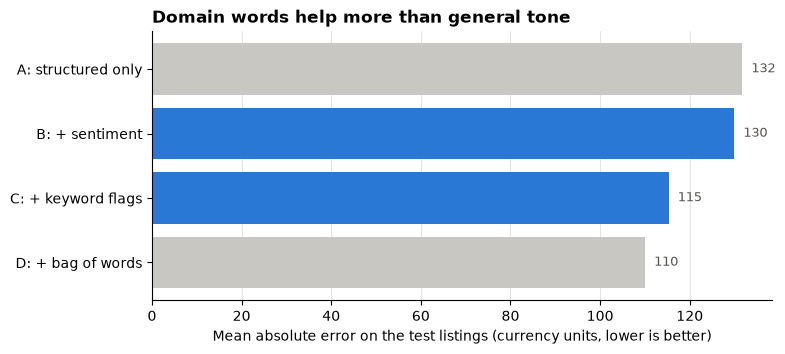

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(results.index[::-1], results["test MAE"][::-1], color=[GREY, BLUE, BLUE, GREY][::-1])
for i, value in enumerate(results["test MAE"][::-1]):
    ax.text(value + 2, i, f"{value:.0f}", va="center", fontsize=9, color=INK)
ax.set_title("Domain words help more than general tone")
ax.set_xlabel("Mean absolute error on the test listings (currency units, lower is better)")
ax.grid(axis="y", visible=False)
plt.show()

Read the table and the chart. Every text feature improves on the structured-only model, but by very different amounts:

- **Sentiment** helps only a little: it measures the seller's tone, which is a noisy signal of condition.
- **Keyword flags** chosen with domain knowledge help much more.
- The **bag of words** lets the model weigh every common word and does best here. With fewer listings or more words it could overfit; always check on the test set.

The lesson is not "sentiment is useless". In data where tone and value move together (for example a property agent who writes glowing notes only about well-finished homes), a sentiment score can be a strong feature. **Whether a text feature helps is an empirical question**: build it, then test it.

---

## Part 6: Pitfalls

### 1. Misreadings

A lexicon gives each word a fixed score, whatever the context. Check a sample of texts and their scores by eye before you trust a score: is "fixer-upper", "bent" or "as is" in the lexicon at all?

### 2. Data leakage

**Leakage** happens when a feature contains information that would not be available at the moment of prediction, often the answer itself. The model then looks brilliant in testing and fails in use.

| Feature | Leak? | Why |
|---|---|---|
| Seller's description written before the sale | No | Known when the price is suggested |
| A note added after the sale: "Sold quickly for 450, buyer was happy" | **Yes** | Contains the price and is written after the sale |
| Number of days the listing stayed online | **Yes** | Only known after the sale; also partly caused by the price |

### 3. Fairness and privacy

Text can carry personal information (names, addresses, health) and can act as a proxy for protected characteristics. Before using text in a model that affects people (loans, hiring, insurance), ask whether you have the right to use it and whether it could treat groups unfairly.

> **Check your understanding**
>
> An insurer wants to predict claim cost from the notes its call-centre staff write during the first call. Which kind of note would be a leak? Which raises a fairness question?

---

## Part 7: Assignment 2 briefing

The full brief, the starter notebook and the marking criteria are in one place: **[Assignment 2: Predictive data mining report](D4_assignment2_predictive_data_mining.md)**. Open it now; we go through it together.

| | |
|---|---|
| **Weight and outcomes** | 6% of the course grade; CLO 1, 2, 3 and 4 |
| **Scenario** | A real-estate analytics firm wants to predict home sale prices from structured data (size, bedrooms, age) and the agent's written description |
| **You do** | Run and complete the starter notebook: generate the data, explore it, turn the descriptions into a **Text Appeal Score** with VADER, fit a multiple linear regression with and without the score, and evaluate it on test data. Then write a five-section business report |
| **You submit** | One combined PDF, report first and notebook as an appendix, on **GAP (Moodle)** |
| **Due** | **Sunday 22 November 2026, 23:59 China Standard Time** |

Everything in this lecture and the regression lecture applies: compare a model **with and without** the text feature on the **test** set, read each coefficient in business language, and check whether the sentiment score really captures what the descriptions say.

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Data mining | A process from business question to deployed model; most work is data preparation |
| Supervised vs unsupervised | With a known target (predict) or without (find structure) |
| Unstructured data | Must be turned into numbers before a model can use it |
| Sentiment feature | One number for tone; quick, but measures tone, not facts |
| Keyword flags | Domain words chosen by people; easy to explain |
| Bag of words | One column per word; flexible, but many columns |
| Evaluation | Compare test errors with and without the text features |
| Pitfalls | Lexicon misreadings, leakage, fairness and privacy |

## Quick reference

| You want to… | Code |
|---|---|
| Sentiment score | `SentimentIntensityAnalyzer().polarity_scores(text)["compound"]` |
| Score a whole column | `df["text"].apply(lambda t: analyzer.polarity_scores(t)["compound"])` |
| Keyword flag | `df["text"].str.lower().str.contains("rust").astype(int)` |
| Bag of words | `CountVectorizer(binary=True, min_df=5, stop_words="english").fit_transform(train_text)` |
| Same words for the test set | `vectorizer.transform(test_text)` |

---

## Closing quiz

1. Name the six steps of CRISP-DM. In which step does turning text into features belong?
2. Give one example each of a supervised and an unsupervised data-mining task in retail.
3. Why can a VADER score rate "no damage at all" as negative?
4. A model with text features has a lower **training** error than one without. Is that enough to keep the text features? What do you check?
5. Give an example of data leakage in a model that predicts whether a customer will cancel a subscription.

---

## Next

- **Assignment 2:** [Predictive data mining report](D4_assignment2_predictive_data_mining.md), due Sunday 22 November.
- **Tomorrow:** financial modelling and spreadsheet simulation in Excel, and [Applied Lab 5](D5_lab_lab5_regression.md) in the afternoon.